# Fashion-MNIST: ANN vs CNN

Fashion-MNIST has 70,000 grayscale 28x28 images of clothing in 10 classes (T-shirt, trouser, pullover, dress, coat, sandal, shirt, sneaker, bag, ankle boot).

1. **ANN baseline** - flatten the image and use one dense layer
2. **CNN** - convolution + pooling keep the 2-D spatial structure of the image

Comparing the two shows why convolutional layers are the standard choice for images.

In [20]:
# Imports (NumPy, Matplotlib, Keras, TensorFlow).
# CNN ON FASHION Data
import keras
import numpy as np
import matplotlib.pyplot as plt
from keras import layers
from keras.datasets import mnist
import tensorflow as tf


In [21]:
# Load Fashion-MNIST: 60,000 training and 10,000 test images.
# Data read
fm = keras.datasets.fashion_mnist
(X_train, y_train), (X_test, y_test) = fm.load_data()

In [22]:
# Shape check: (samples, height, width).
X_train.shape

(60000, 28, 28)

In [23]:
# Shape check for the test set.
X_test.shape

(10000, 28, 28)

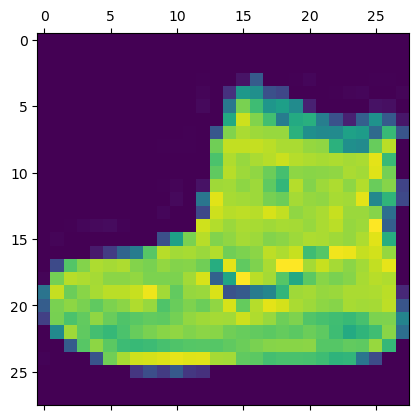

In [24]:
# Display the first training image.
plt.matshow(X_train[0])

In [25]:
# Its label (an integer 0-9).
y_train[0]


np.uint8(9)

In [26]:
# Normalise pixel values from 0-255 to 0-1 for faster, more stable training.
X_train = X_train/255
X_test = X_test/255

In [27]:
# Inspect the normalised pixel values.
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [28]:
# Flatten 28x28 images into 784-long vectors for the dense (ANN) model.
X_train_flattened = X_train.reshape(len(X_train), 28*28)
X_test_flattened = X_test.reshape(len(X_test), 28*28)

In [29]:
# Shape check after flattening.
X_train_flattened.shape

(60000, 784)

In [30]:
# ANN baseline: a single dense layer (784 -> 10).
model = keras.Sequential([
    keras.layers.Dense(10, input_shape = (784,), activation= 'sigmoid')
])
model.compile(optimizer='adam', loss = 'sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train_flattened, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7959 - loss: 0.6039
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8425 - loss: 0.4623
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8494 - loss: 0.4372
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8538 - loss: 0.4227
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8577 - loss: 0.4143


In [31]:
# Evaluate on the 10,000 test images.
model.evaluate(X_test_flattened, y_test)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8439 - loss: 0.4502


[0.45019033551216125, 0.8439000248908997]

In [32]:
# Predict class probabilities for the whole test set.
y_predicted = model.predict(X_test_flattened)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 895us/step
